# MADT 7202 Mid-Term · Swiftie Bridge Artists
**Decision:** แบรนด์ที่อยากเจาะกลุ่มแฟน Taylor Swift ควรเลือกศิลปินคนไหนมาทำ campaign — คนที่ *ใกล้ Swift* และ *เป็นสะพานไปฐานแฟนกลุ่มอื่น*

**Data:** Last.fm API (`artist.getSimilar`, `artist.getTopTags`) · Data courtesy of Last.fm (https://www.last.fm)

วิธีใช้: ใส่ `API_KEY` ในเซลล์ถัดไป แล้ว **Runtime → Run all** (ใช้เวลาดึงข้อมูลราว 3–6 นาที)

In [ ]:
# ==== CONFIG ====
API_KEY = "YOUR API KEY"
SEED = "Taylor Swift"
LIMIT_L1 = 30        # similar artists of the seed (layer 1)
LIMIT_L2 = 30        # similar artists of each layer-1 artist (layer 2)
CUTOFF = 0.30        # main pruning cutoff on similarity (match)
SWEEP = [0.20, 0.30, 0.40]
MIN_DEGREE = 2
TOP_N = 5

# Tags that connect to everything and carry no genre meaning (generic-term exclusion)
GENERIC_TAGS = {"seen live","female vocalists","female vocalist","male vocalists","favorites",
    "favourite","favorite","american","british","canadian","australian","singer-songwriter",
    "all","love","beautiful","awesome","00s","10s","2010s","2020s","90s","under 2000 listeners",
    "spotify","my favorite","favourites","usa","english","female","male","pop"}

In [ ]:
import requests, json, time, os, datetime
import pandas as pd, numpy as np, networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

BASE = "https://ws.audioscrobbler.com/2.0/"
CACHE = "lastfm_cache"; os.makedirs(CACHE, exist_ok=True)

def call(method, artist, limit=None):
    key = f"{method}__{artist}__{limit}".replace("/", "_")
    path = os.path.join(CACHE, key[:150] + ".json")
    if os.path.exists(path):
        return json.load(open(path))
    params = {"method": method, "artist": artist, "api_key": API_KEY, "format": "json", "autocorrect": 1}
    if limit: params["limit"] = limit
    for attempt in range(3):
        r = requests.get(BASE, params=params, timeout=20)
        if r.status_code == 200:
            data = r.json(); json.dump(data, open(path, "w")); time.sleep(0.25)  # stay well under rate limit
            return data
        time.sleep(2 * (attempt + 1))
    return {}

def similar(artist, limit):
    d = call("artist.getsimilar", artist, limit)
    return [(a["name"], float(a["match"])) for a in d.get("similarartists", {}).get("artist", [])]

def top_tags(artist):
    d = call("artist.gettoptags", artist)
    return [(t["name"].lower().strip(), int(t["count"])) for t in d.get("toptags", {}).get("tag", [])]

## 1. เก็บข้อมูล (2-hop crawl จาก seed)

In [ ]:
FETCHED_AT = datetime.datetime.now().isoformat(timespec="minutes")
rows = []
l1 = similar(SEED, LIMIT_L1)
for name, m in l1:
    rows.append({"source": SEED, "target": name, "match": m, "layer": 1})
for i, (name, _) in enumerate(l1, 1):
    for t, m in similar(name, LIMIT_L2):
        rows.append({"source": name, "target": t, "match": m, "layer": 2})
    print(f"\r{i}/{len(l1)} {name}          ", end="")

raw = pd.DataFrame(rows); raw["fetched_at"] = FETCHED_AT
raw.to_csv("raw_similar_edges.csv", index=False)
L1 = {n for n, _ in l1}
swift_sim = dict(l1)
print(f"\nRecords: {len(raw)} | layer-1 artists: {len(L1)} | unique artists: {pd.unique(raw[['source','target']].values.ravel()).size}")

30/30 Camila Cabello          
Records: 929 | layer-1 artists: 30 | unique artists: 337


## 2. สร้าง graph
- Node = ศิลปิน · Edge = Last.fm ระบุว่ามีคนฟังซ้อนกัน · Weight = similarity (ถ้า A→B ≠ B→A ใช้ max)
- **ลบ seed (Taylor Swift) ออกก่อน rank** · ตัด edge < cutoff · ตัด node ที่ degree < 2 · เก็บ largest component

In [ ]:
def build_graph(raw, cutoff, min_degree=MIN_DEGREE):
    G = nx.Graph()
    for r in raw.itertuples():
        a, b = r.source, r.target
        if a == b: continue
        w = max(r.match, G[a][b]["weight"]) if G.has_edge(a, b) else r.match
        G.add_edge(a, b, weight=w)
    G.remove_nodes_from([n for n in list(G) if n.lower() == SEED.lower()])   # seed exclusion
    G.remove_edges_from([(u, v) for u, v, w in G.edges(data="weight") if w < cutoff])
    while True:
        low = [n for n, d in G.degree() if d < min_degree]
        if not low: break
        G.remove_nodes_from(low)
    if G.number_of_nodes():
        G = G.subgraph(max(nx.connected_components(G), key=len)).copy()
    for u, v, w in G.edges(data="weight"):
        G[u][v]["dist"] = 1 - w + 1e-6   # strong similarity = short path
    return G

def metrics(G):
    btw = nx.betweenness_centrality(G, weight="dist", normalized=True)
    df = pd.DataFrame({"artist": list(G)})
    df["betweenness"] = df.artist.map(btw)
    df["degree"] = df.artist.map(dict(G.degree()))
    df["swift_similarity"] = df.artist.map(swift_sim).fillna(0.0)
    df["in_layer1"] = df.artist.isin(L1)
    return df.sort_values("betweenness", ascending=False).reset_index(drop=True)

G = build_graph(raw, CUTOFF)
M = metrics(G)
print(f"cutoff={CUTOFF}: nodes={G.number_of_nodes()} edges={G.number_of_edges()}")

cutoff=0.3: nodes=158 edges=520


## 3. Genre tags (ใช้ลงสีและเป็น construction ทางเลือก) — ตัด generic tags ออก

In [ ]:
tags = {}
for i, a in enumerate(G.nodes(), 1):
    tags[a] = [(t, c) for t, c in top_tags(a) if t not in GENERIC_TAGS][:10]
    print(f"\r{i}/{G.number_of_nodes()}", end="")
M["primary_tag"] = M.artist.map(lambda a: tags[a][0][0] if tags.get(a) else "unknown")
pd.DataFrame([{"artist": a, "tag": t, "count": c} for a, ts in tags.items() for t, c in ts]).to_csv("artist_tags.csv", index=False)

# Group the long tail of tags into a few colour groups for the figure
top_groups = M.primary_tag.value_counts().head(6).index.tolist()
M["genre_group"] = M.primary_tag.where(M.primary_tag.isin(top_groups), "other")
print("\n", M.genre_group.value_counts())

158/158
 genre_group
other           58
indie pop       26
country         24
rnb             16
dance           12
my top songs    11
indie           11
Name: count, dtype: int64


## 4. Findings: ใครใกล้ Swift และเป็นสะพาน
Candidate = ศิลปินชั้นที่ 1 (แฟนซ้อนกับ Swift โดยตรง) จัดอันดับด้วย betweenness

In [ ]:
cand = M[M.in_layer1].copy()
cand["sim_rank"] = cand.swift_similarity.rank(ascending=False).astype(int)
cand["btw_rank"] = cand.betweenness.rank(ascending=False).astype(int)
# neighbours outside the Swift layer-1 circle = reach into new audiences
cand["new_reach"] = cand.artist.map(lambda a: sum(1 for n in G[a] if n not in L1))
cand["neighbour_genres"] = cand.artist.map(lambda a: M.set_index("artist").loc[list(G[a]), "genre_group"].nunique())
cols = ["artist","swift_similarity","sim_rank","betweenness","btw_rank","degree","new_reach","neighbour_genres","primary_tag"]
shortlist = cand.sort_values("betweenness", ascending=False)[cols]
shortlist.to_csv("shortlist.csv", index=False)
display(shortlist.head(10).round(3))

top_sim = cand.sort_values("swift_similarity", ascending=False).iloc[0]
top_btw = shortlist.iloc[0]
print(f"Most similar to Swift: {top_sim.artist} (sim {top_sim.swift_similarity:.2f}, betweenness {top_sim.betweenness:.3f}, new_reach {top_sim.new_reach})")
print(f"Best bridge:          {top_btw.artist} (sim {top_btw.swift_similarity:.2f}, betweenness {top_btw.betweenness:.3f}, new_reach {top_btw.new_reach})")
rho, p = spearmanr(cand.swift_similarity, cand.betweenness)
print(f"Spearman(similarity, betweenness) among candidates = {rho:.2f} (p={p:.3f})  -> low rho = a ranked list by similarity would pick different artists")

,artist,swift_similarity,sim_rank,betweenness,btw_rank,degree,new_reach,neighbour_genres,primary_tag
0,Gracie Abrams,0.909,2,0.521,1,25,13,5,indie pop
1,Maisie Peters,0.473,4,0.320,2,25,17,6,folk
2,Olivia Rodrigo,0.853,3,0.305,3,25,10,6,pop rock
3,Kelsea Ballerini,0.460,5,0.247,4,19,16,2,country
4,Halsey,0.293,19,0.217,5,28,16,6,indie pop
5,Troye Sivan,0.265,26,0.213,6,26,15,4,indie pop
6,Lorde,0.416,7,0.175,7,26,17,3,indie pop
7,Conan Gray,0.377,12,0.173,8,19,10,5,indie pop
8,Katy Perry,0.285,22,0.170,9,28,21,4,pop rock
9,Chappell Roan,0.443,6,0.147,10,26,13,5,indie pop


Most similar to Swift: Sabrina Carpenter (sim 1.00, betweenness 0.124, new_reach 11)
Best bridge:          Gracie Abrams (sim 0.91, betweenness 0.521, new_reach 13)
Spearman(similarity, betweenness) among candidates = 0.52 (p=0.003)  -> low rho = a ranked list by similarity would pick different artists


## 5. Robustness check 1 — cutoff sweep

In [ ]:
sweep_rows, tops = [], {}
for c in SWEEP:
    Gc = build_graph(raw, c); Mc = metrics(Gc)
    t = Mc[Mc.in_layer1].head(TOP_N).artist.tolist(); tops[c] = t
    sweep_rows.append({"cutoff": c, "nodes": Gc.number_of_nodes(), "edges": Gc.number_of_edges(),
                       f"top{TOP_N}_bridges": ", ".join(t)})
sweep = pd.DataFrame(sweep_rows)
base = set(tops[CUTOFF])
sweep[f"overlap_with_{CUTOFF}"] = [f"{len(base & set(tops[c]))}/{TOP_N}" for c in SWEEP]
sweep["#1_bridge"] = [tops[c][0] if tops[c] else "-" for c in SWEEP]
sweep.to_csv("robustness_cutoff.csv", index=False)
display(sweep)

,cutoff,nodes,edges,top5_bridges,overlap_with_0.3,#1_bridge
0,0.2,174,577,"Gracie Abrams, Olivia Rodrigo, Maisie Peters, ...",5/5,Gracie Abrams
1,0.3,158,520,"Gracie Abrams, Maisie Peters, Olivia Rodrigo, ...",5/5,Gracie Abrams
2,0.4,114,354,"Gracie Abrams, Olivia Rodrigo, Halsey, Troye S...",3/5,Gracie Abrams


## 6. Robustness check 2 — construction ทางเลือก: shared-tag Jaccard แทน similarity score
Edge = Jaccard ของ genre tags (ไม่ใช้พฤติกรรมการฟัง) → bridge ยังเป็นคนเดิมไหม?

In [ ]:
def tag_graph(nodes, thr=0.25):
    S = {a: {t for t, _ in tags.get(a, [])} for a in nodes}
    H = nx.Graph(); H.add_nodes_from(nodes)
    nl = list(nodes)
    for i in range(len(nl)):
        for j in range(i + 1, len(nl)):
            a, b = S[nl[i]], S[nl[j]]
            if a and b:
                jac = len(a & b) / len(a | b)
                if jac >= thr: H.add_edge(nl[i], nl[j], weight=jac, dist=1 - jac + 1e-6)
    return H

H = tag_graph(list(G.nodes()))
bt = nx.betweenness_centrality(H, weight="dist", normalized=True)
alt_top = [a for a, _ in sorted(bt.items(), key=lambda x: -x[1]) if a in L1][:TOP_N]
print(f"Tag-Jaccard graph: nodes={H.number_of_nodes()} edges={H.number_of_edges()}")
print(f"Top{TOP_N} bridges (similarity graph): {tops[CUTOFF]}")
print(f"Top{TOP_N} bridges (tag graph):        {alt_top}")
print(f"Overlap: {len(set(alt_top) & base)}/{TOP_N}")

Tag-Jaccard graph: nodes=158 edges=987
Top5 bridges (similarity graph): ['Gracie Abrams', 'Maisie Peters', 'Olivia Rodrigo', 'Kelsea Ballerini', 'Halsey']
Top5 bridges (tag graph):        ['Kelsea Ballerini', 'Halsey', 'Chappell Roan', 'Selena Gomez', 'Katy Perry']
Overlap: 2/5


## 7. Figures

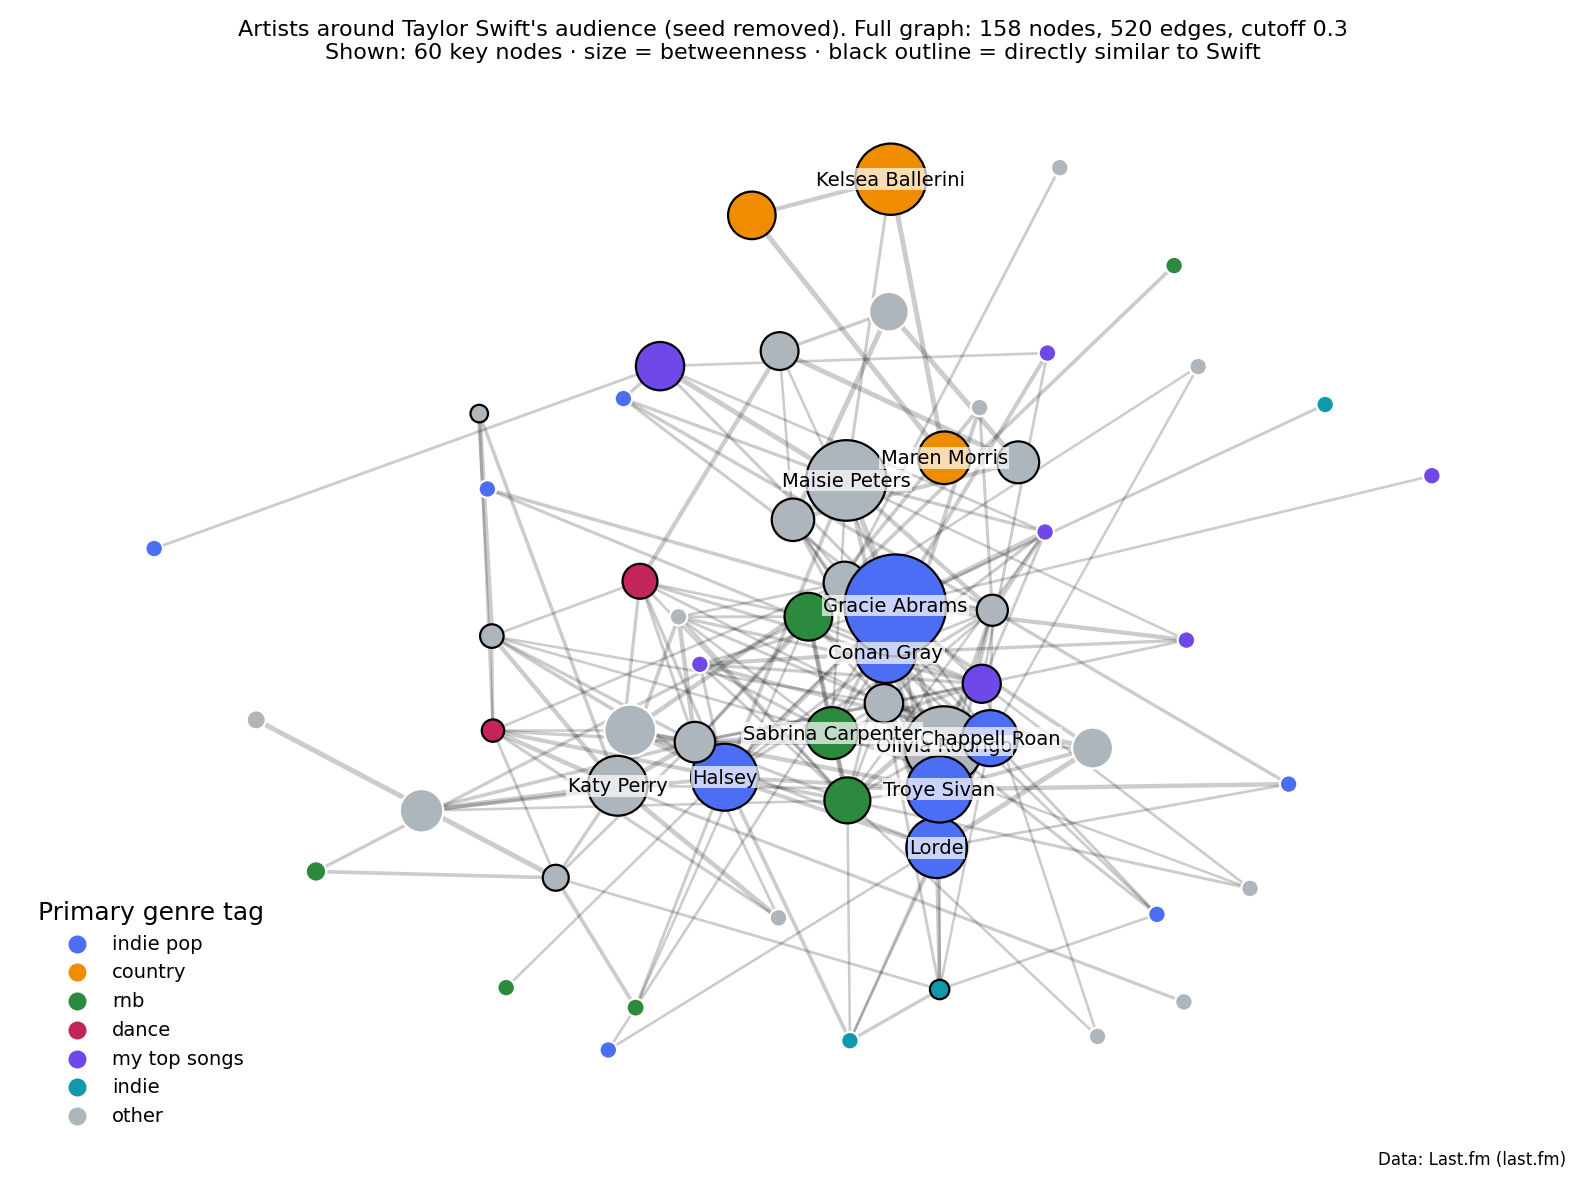

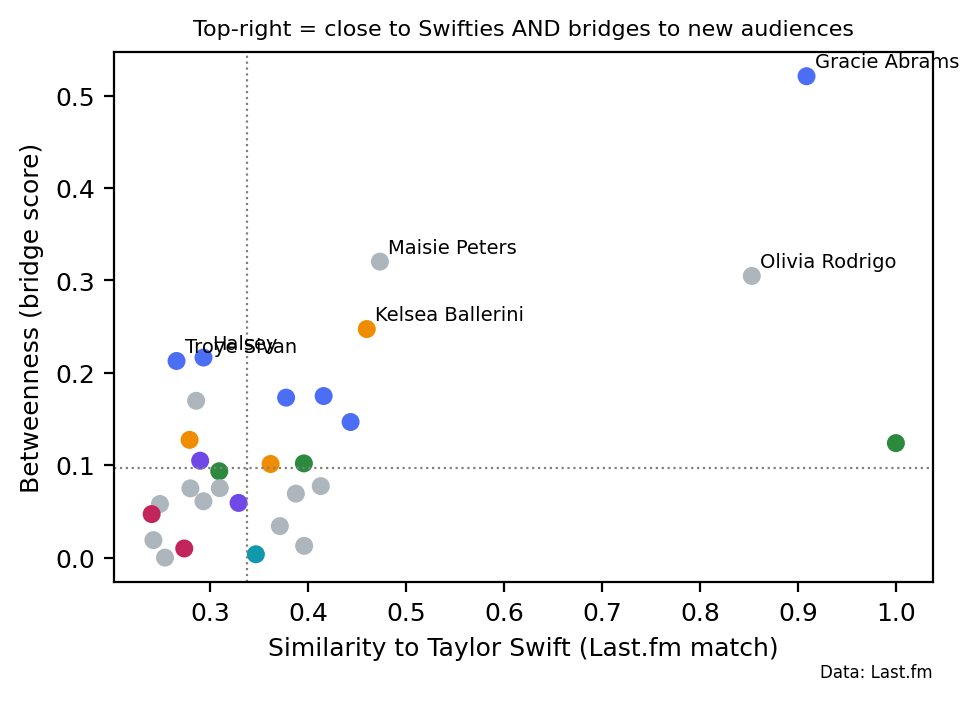

In [ ]:
plt.rcParams.update({"font.size": 9})
palette = ["#4C6EF5","#F08C00","#2B8A3E","#C2255C","#7048E8","#1098AD","#ADB5BD"]
groups = [g for g in M.genre_group.value_counts().index if g != "other"] + ["other"]
cmap = {g: palette[i % len(palette)] for i, g in enumerate(groups)}
attr = M.set_index("artist")

# Figure shows the most important ~60 nodes (all layer-1 + top bridges); metrics are computed on the full graph
FIG_MAX_NODES = 60
keep = [a for a in M.artist if a in L1]
keep += [a for a in M.artist if a not in keep][: max(0, FIG_MAX_NODES - len(keep))]
F = G.subgraph(keep).copy()
F.remove_edges_from([(u, v) for u, v, w in F.edges(data="weight") if w < CUTOFF + 0.1])  # lighter edges only for drawing
F.remove_nodes_from([n for n, d in F.degree() if d == 0])

fig, ax = plt.subplots(figsize=(8, 6), dpi=200)
pos = nx.spring_layout(F, weight="weight", seed=7, k=0.6)
nx.draw_networkx_edges(F, pos, ax=ax, alpha=0.2, width=[0.3 + 1.5 * F[u][v]["weight"] for u, v in F.edges()])
sizes = [40 + 2500 * attr.loc[n, "betweenness"] for n in F]
nx.draw_networkx_nodes(F, pos, ax=ax, node_size=sizes, node_color=[cmap[attr.loc[n, "genre_group"]] for n in F],
                       edgecolors=["black" if n in L1 else "white" for n in F], linewidths=0.8)
label_nodes = [a for a in M.artist if a in F][:12]
nx.draw_networkx_labels(F, pos, labels={n: n for n in label_nodes}, font_size=7, ax=ax,
                        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=0.5))
for g in groups: ax.scatter([], [], c=cmap[g], label=g, s=30)
ax.legend(title="Primary genre tag", loc="lower left", fontsize=7, frameon=False)
ax.set_title(f"Artists around Taylor Swift's audience (seed removed). Full graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges, cutoff {CUTOFF}\n"
             f"Shown: {F.number_of_nodes()} key nodes · size = betweenness · black outline = directly similar to Swift", fontsize=8)
ax.text(1, -0.02, "Data: Last.fm (last.fm)", transform=ax.transAxes, ha="right", fontsize=6)
ax.axis("off"); plt.tight_layout(); plt.savefig("fig_network.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(5, 3.6), dpi=200)
ax.scatter(cand.swift_similarity, cand.betweenness, c=[cmap[g] for g in cand.genre_group], s=30)
for r in cand.sort_values("betweenness", ascending=False).head(6).itertuples():
    ax.annotate(r.artist, (r.swift_similarity, r.betweenness), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.axvline(cand.swift_similarity.median(), ls=":", c="grey", lw=0.8); ax.axhline(cand.betweenness.median(), ls=":", c="grey", lw=0.8)
ax.set_xlabel("Similarity to Taylor Swift (Last.fm match)"); ax.set_ylabel("Betweenness (bridge score)")
ax.set_title("Top-right = close to Swifties AND bridges to new audiences", fontsize=8)
ax.text(1, -0.18, "Data: Last.fm", transform=ax.transAxes, ha="right", fontsize=6)
plt.tight_layout(); plt.savefig("fig_scatter.png", bbox_inches="tight"); plt.show()

## 8. ตัวเลขสำหรับหน้า A4

In [ ]:
summary = {
  "Source": "Last.fm API artist.getSimilar + artist.getTopTags",
  "Fetched at": FETCHED_AT,
  "Raw records (similarity pairs)": len(raw),
  "Unique artists before pruning": int(pd.unique(raw[['source','target']].values.ravel()).size),
  "Final nodes / edges (cutoff %.2f)" % CUTOFF: f"{G.number_of_nodes()} / {G.number_of_edges()}",
  "Seed excluded": SEED,
  "Most similar to Swift": f"{top_sim.artist} (sim {top_sim.swift_similarity:.2f}, btw {top_sim.betweenness:.3f})",
  "#1 bridge": f"{top_btw.artist} (sim {top_btw.swift_similarity:.2f}, btw {top_btw.betweenness:.3f}, {top_btw.new_reach} neighbours outside Swift circle)",
  "Spearman sim vs btw": round(rho, 2),
  "Cutoff sweep #1 bridge": " / ".join(f"{c}: {tops[c][0] if tops[c] else '-'}" for c in SWEEP),
  "Tag-graph top-5 overlap": f"{len(set(alt_top) & base)}/{TOP_N}",
}
pd.Series(summary).to_frame("value").to_csv("summary_for_A4.csv")
pd.Series(summary).to_frame("value")

,value
Source,Last.fm API artist.getSimilar + artist.getTopTags
Fetched at,2026-10-16T10:46
Raw records (similarity pairs),929
Unique artists before pruning,337
Final nodes / edges (cutoff 0.30),158 / 520
Seed excluded,Taylor Swift
Most similar to Swift,"Sabrina Carpenter (sim 1.00, btw 0.124)"
#1 bridge,"Gracie Abrams (sim 0.91, btw 0.521, 13 neighbo..."
Spearman sim vs btw,0.52
Cutoff sweep #1 bridge,0.2: Gracie Abrams / 0.3: Gracie Abrams / 0.4:...


In [ ]:
!zip results.zip *.csv *.png

  adding: artist_tags.csv (deflated 74%)
  adding: raw_similar_edges.csv (deflated 79%)
  adding: robustness_cutoff.csv (deflated 48%)
  adding: shortlist.csv (deflated 44%)
  adding: summary_for_A4.csv (deflated 35%)
  adding: fig_network.png (deflated 8%)
  adding: fig_scatter.png (deflated 11%)
